# Проект спринта 25. Выявление подозрительных транзакций на сайте международного ретейлера электроники.
### Цель
Разработать модель классификации, которая будет анализировать транзакции в реальном времени и блокировать подозрительные.

### Постановка задачи в терминах машинного обучения
- Тип задачи машинного обучения: бинарная классификация.
- Целевая переменная - идентификатор класса `fraud_flag` (0/1), 1 соответствует классификации транзакции как подозрительной.
- Модели машинного обучения - градиентный бустинг (реализация в библиотеке XGBoost).
- Основные метрики - Recall, ROC-AUC. Вспомогательные метрики - Accuracy, F1-score, Precision.
- Для подбора оптимального набора гиперпараметров следует использовать байесовскую оптимизацию (библиотека Optuna).
- Для интерпретации модели по важности признаков следует использовать SHAP.
- Необходимо обеспечить воспроизводимость результатов при помощи указания фиксированного значения `random_state`.
- Результаты экспериментов (модели, значения метрик и артефакты) необходимо сохранить в MLFlow. Сохранённые артефакты должны включать диаграмму значимости признаков SHAP, кривую обучения, матрицу ошибок.

### Задачи
1. Загрузка датасета.
2. Исследовательский анализ данных.
3. Предобработка данных - обработка пропусков, дубликатов и выбросов; добавление новых признаков.
4. Проверка гипотез о связи фрода с международными транзакциями, методами оплаты, днями недели и типами устройств.
5. Предобработка данных для машинного обучения, формирование обучающей и валидационной выборок.
6. Обучение базовой модели градиентного бустинга XGBoost с параметрами по умолчанию, ее сравнение с `DummyClassifier`.
7. Подбор гиперпараметров для градиентного бустинга при помощи библиотеки Optuna с использованием валидационной выборки.
8. Сохранение результатов экспериментов (моделей, метрик и артефактов) в MLFlow.
9. Выбор эксперимента с лучшим значением метрик и регистрация соответствующей модели в MLFlow.

## Описание данных

В файле [retail_fraud_detection_100k.csv](https://code.s3.yandex.net/datasets/retail_fraud_detection_100k.csv) находится датасет, который содержит 100 000 записей. Эти данные описывают поведенческие паттерны клиентов, их транзакционную активность и различные индикаторы, которые помогают выявлять подозрительные действия.

Всего в датасете представлена 21 колонка:

- `transaction_id` (тип `str` ) — уникальный идентификатор транзакции ;
- `customer_id` (тип `str`) — уникальный идентификатор пользователя;
- `transaction_timestamp` (тип `timestamp`) — время совершения транзакции;
- `transaction_amount` (тип `float`) — сумма транзакции;
- `payment_method` (тип `str`) — способ оплаты;
- `device_type` (тип `str`) — тип устройства, с которого совершён платёж;
- `location` (тип `str`) — локация, где совершена транзакция;
- `merchant_category` (тип `str`) — категория продавца;
- `is_international` (тип `int`) — флаг международной транзакции;
- `transaction_frequency_24h` (тип `int`) — количество транзакций клиента за последние 24 часа;
- `avg_transaction_amount_7d` (тип `float`) — средняя сумма транзакций клиента за последние 7 дней;
- `failed_transaction_count_24h` (тип `int`) — количество неудачных транзакций за последние 24 часа;
- `account_age_days` (тип `int`) — «возраст» аккаунта пользователя в днях;
- `previous_fraud_flag` (тип `int`) — флаг наличия мошеннических транзакций у клиента в прошлом;
- `unusual_amount_flag` (тип `int`) — флаг нетипично высокой или низкой суммы транзакции;
- `unusual_location_flag` (тип `int`) — флаг совершения транзакции в нетипичном для клиента местоположении;
- `multiple_transactions_short_time` (тип `int`) — флаг нескольких транзакций, совершённых за короткий промежуток времени;
- `high_risk_device_flag` (тип `int`) — флаг использования устройства, отмеченного как высокорисковое;
- `velocity_flag` (тип `int`) — флаг подозрительно высокой частоты (скорости) транзакций;
- `fraud_flag` (тип `int`) — флаг фрода, а именно того, является ли транзакция мошеннической. Обратите внимание, что это целевая переменная для задачи;
- `fraud_risk` (тип `int` ) — категория риска мошенничества.


## 1. Подготовка среды и загрузка данных
### 1.1. Установка библиотек

In [1]:
%pip install -q mlflow==3.6.0 pandas boto3 optuna phik scikit-learn seaborn matplotlib dotenv jinja2 shap xgboost


[notice] A new release of pip is available: 26.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### 1.2. Импорт необходимых библиотек

In [2]:
import os
import math
import time
from urllib.request import urlopen
from dotenv import load_dotenv
from itertools import product

# Библиотеки для вычислений и работы с датасетами
import pandas as pd
import numpy as np
import phik

# Библиотеки машинного обучения
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, accuracy_score, precision_score, RocCurveDisplay,\
    roc_auc_score, roc_curve, recall_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import learning_curve
from sklearn.base import clone
from sklearn.dummy import DummyClassifier

# Критерий χ^2 для проверки гипотез
from scipy.stats import chi2_contingency

from xgboost import XGBClassifier

# Подбор гиперпараметров
import optuna

# Оценка важности признаков
import shap

# Библиотеки для построения графиков
import seaborn as sns
import matplotlib.pyplot as plt
import plot_utils as pu

# MLFlow
import mlflow
import mlflow.sklearn

# Сериализация пайплайна
import joblib

# Для форматирования в HTML
from IPython.display import display, HTML, Markdown

/Users/texnhmakph/Projects/Yandex DS/ds-yandex/.venv312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.3. Загрузка данных

In [3]:
# Константы и общие настройки
RANDOM_SEED = 42
MLFLOW_EXPERIMENT_NAME = 'fraud_detection_classification'
MLFLOW_REGISTRY_MODEL_NAME = 'FraudDetectionModel'

pd.options.display.float_format = '{:.4f}'.format

BASE_URL = "https://code.s3.yandex.net/"

def load_dataset(file_name, **kwargs):
    try:
        if os.path.exists(file_name):
            return pd.read_csv(file_name, **kwargs)
        else:
            return pd.read_csv(BASE_URL + file_name, **kwargs)
    except:
        print("Ошибка загрузки датасета")
        raise

def show_dataset_info(df, title):
    display(HTML(f"<h2>{title}</h2>"))
    df.info()
    display(df.head())
    display(HTML("<h3>Числовые параметры</h3>"))
    display(df.select_dtypes(include='number').describe())
    display(HTML("<h3>Кардинальность категориальных параметров</h3>"))
    display(df.select_dtypes(include='object').nunique())

df = load_dataset("datasets/retail_fraud_detection_100k.csv")
show_dataset_info(df, "Информация о датасете")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 21 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   transaction_id                    100000 non-null  object 
 1   customer_id                       100000 non-null  object 
 2   transaction_timestamp             100000 non-null  object 
 3   transaction_amount                100000 non-null  float64
 4   payment_method                    100000 non-null  object 
 5   device_type                       100000 non-null  object 
 6   location                          100000 non-null  object 
 7   merchant_category                 100000 non-null  object 
 8   is_international                  100000 non-null  int64  
 9   transaction_frequency_24h         100000 non-null  int64  
 10  avg_transaction_amount_7d         100000 non-null  float64
 11  failed_transaction_count_24h      100000 non-null  in

,transaction_id,customer_id,transaction_timestamp,transaction_amount,payment_method,device_type,location,merchant_category,is_international,transaction_frequency_24h,...,failed_transaction_count_24h,account_age_days,previous_fraud_flag,unusual_amount_flag,unusual_location_flag,multiple_transactions_short_time,high_risk_device_flag,velocity_flag,fraud_flag,fraud_risk
0,T0000001,C20953,2026-03-04 19:56:23.679173,56.3100,Debit Card,Tablet,Canada,Fashion,0,13,...,4,1054,0,0,0,1,0,1,0,Medium
1,T0000002,C24133,2026-03-09 19:56:23.679330,20.3500,Credit Card,Tablet,India,Electronics,0,3,...,2,97,0,0,0,0,0,0,0,Low
2,T0000003,C07165,2026-01-01 19:56:23.679362,48.7200,Debit Card,Tablet,UK,Travel,0,8,...,4,779,1,0,0,0,0,0,0,Medium
3,T0000004,C19310,2025-12-09 19:56:23.679385,153.6200,Debit Card,Mobile,Australia,Fashion,0,14,...,3,286,1,1,0,1,0,1,1,High
4,T0000005,C25019,2025-11-09 19:56:23.679409,115.3200,PayPal,Mobile,India,Gaming,0,10,...,3,866,0,0,0,1,0,0,0,Low


,transaction_amount,is_international,transaction_frequency_24h,avg_transaction_amount_7d,failed_transaction_count_24h,account_age_days,previous_fraud_flag,unusual_amount_flag,unusual_location_flag,multiple_transactions_short_time,high_risk_device_flag,velocity_flag,fraud_flag
count,100000.0000,100000.0000,100000.0000,100000.0000,100000.0000,100000.0000,100000.0000,100000.0000,100000.0000,100000.0000,100000.0000,100000.0000,100000.0000
mean,120.4754,0.4980,7.4899,109.8110,2.0036,1005.3294,0.5001,0.2295,0.4980,0.4270,0.1010,0.2840,0.4751
std,119.7873,0.5000,4.0240,51.8929,1.4149,573.3137,0.5000,0.4205,0.5000,0.4947,0.3013,0.4509,0.4994
min,0.0000,0.0000,1.0000,20.0000,0.0000,10.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
25%,34.8200,0.0000,4.0000,64.9100,1.0000,510.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
50%,84.1300,0.0000,7.0000,109.7800,2.0000,1004.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
75%,167.5200,1.0000,11.0000,154.6725,3.0000,1501.2500,1.0000,0.0000,1.0000,1.0000,0.0000,1.0000,1.0000
max,1548.5200,1.0000,14.0000,200.0000,4.0000,1999.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


transaction_id           100000
customer_id               28955
transaction_timestamp    100000
payment_method                5
device_type                   3
location                      6
merchant_category             6
fraud_risk                    3
dtype: int64

In [4]:
# Количество транзакций с нулевой суммой
print(f"Транзакций с нулевой суммой: {df[df['transaction_amount'] == 0.0].shape[0]}")

Транзакций с нулевой суммой: 4


- Пропуски в датасете отсутствуют.
- Имеются транзакции с нулевой суммой в количестве 4 шт. Их можно удалить, очевидно, это результат ошибки.
- Аномалии в числовых параметрах отсутствуют.

In [5]:
TARGET = 'fraud_flag'

# Удаление транзакций с нулевой суммой
df = df[df['transaction_amount'] > 0.0]

# Преобразование столбца `transaction_timestamp` во временную метку и создание дополнительных признаков
df['transaction_timestamp'] = pd.to_datetime(df['transaction_timestamp'], format="%Y-%m-%d %H:%M:%S.%f")
df['transaction_hour'] = df['transaction_timestamp'].dt.hour
df['transaction_dow'] = df['transaction_timestamp'].dt.day_of_week

## 2. Исследовательский анализ данных
### 2.1. Распределение целевой переменной

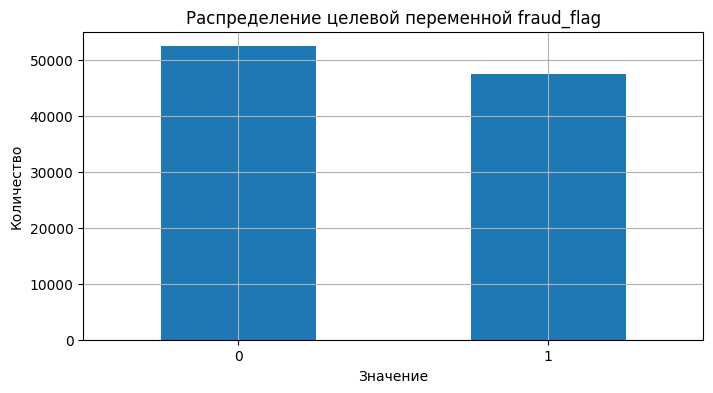

In [6]:
pu.draw_barplot(df[TARGET].value_counts(), "Распределение целевой переменной fraud_flag", "Значение", "Количество")

- Классы почти сбалансированы, что необычно для фрод-анализа - обычно количество мошеннических транзакций значительно меньше.

### 2.2. Распределение числовых признаков

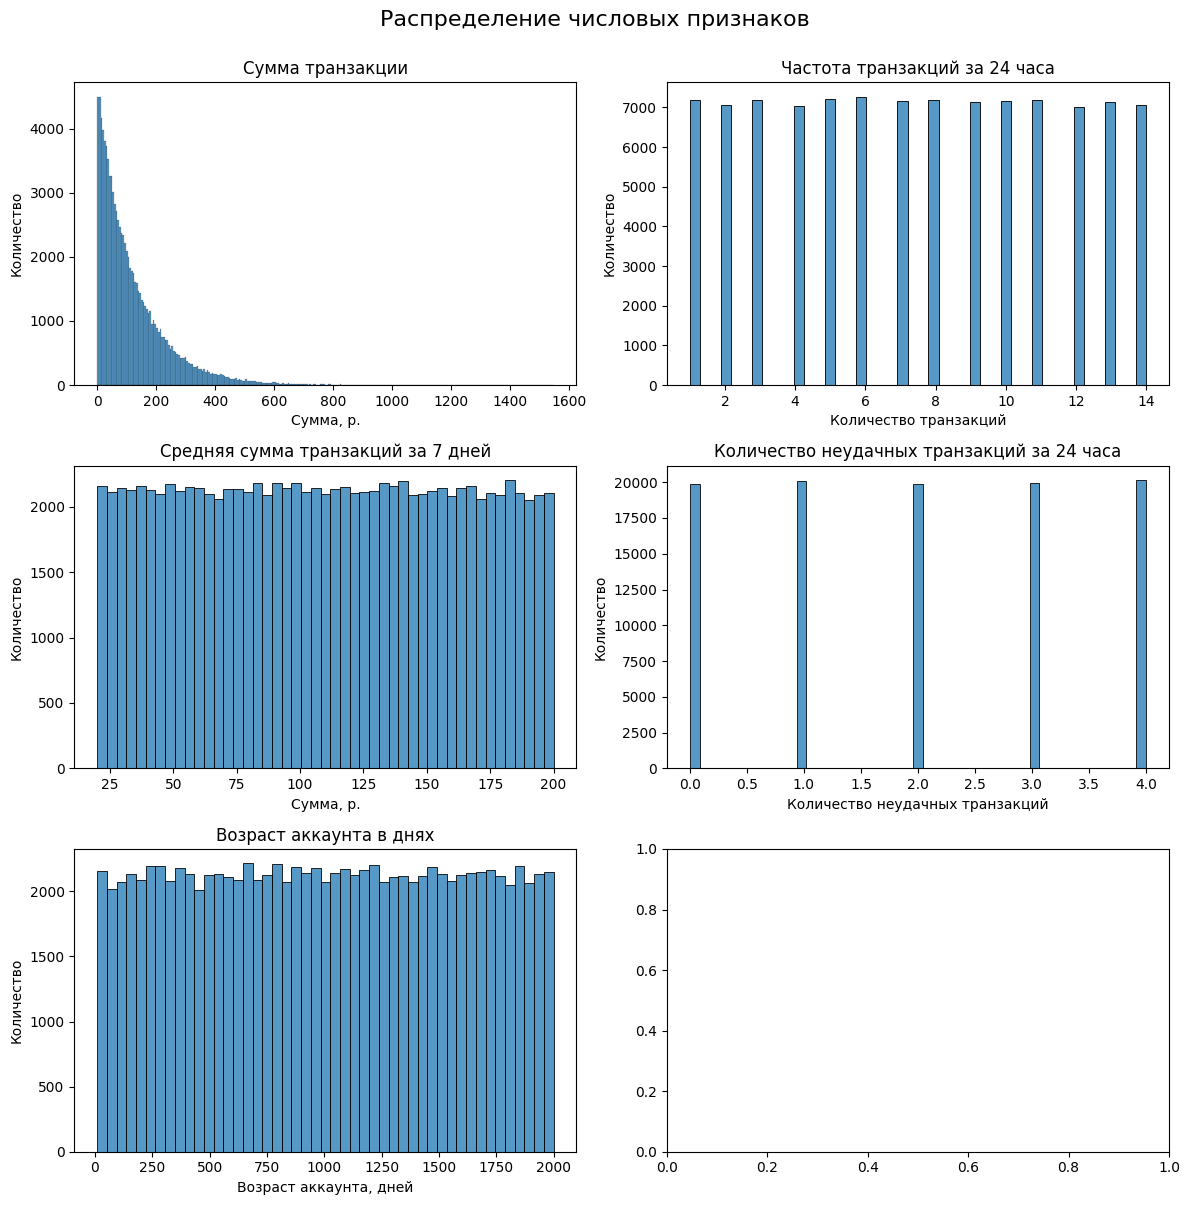

In [7]:
NUMBER_FEATURES = [
    'transaction_amount',
    'transaction_frequency_24h',
    'avg_transaction_amount_7d',
    'failed_transaction_count_24h',
    'account_age_days'
]

number_feat_desc = [
    {"data": df, "x": 'transaction_amount', "title": "Сумма транзакции", "xlabel": "Сумма, р.", "ylabel": "Количество"},
    {"data": df, "x": 'transaction_frequency_24h', "title": "Частота транзакций за 24 часа", "xlabel": "Количество транзакций", "ylabel": "Количество"},
    {"data": df, "x": 'avg_transaction_amount_7d', "title": "Средняя сумма транзакций за 7 дней", "xlabel": "Сумма, р.", "ylabel": "Количество"},
    {"data": df, "x": 'failed_transaction_count_24h', "title": "Количество неудачных транзакций за 24 часа", "xlabel": "Количество неудачных транзакций", "ylabel": "Количество"},
    {"data": df, "x": 'account_age_days', "title": "Возраст аккаунта в днях", "xlabel": "Возраст аккаунта, дней", "ylabel": "Количество"}
]

pu.show_histogram_grid(number_feat_desc, "Распределение числовых признаков")

- Сумма транзакции имеет правостороннее асимметричное распределение. 
- Остальные признаки распределены равномерно.

### 2.3. Распределение категориальных и булевых признаков

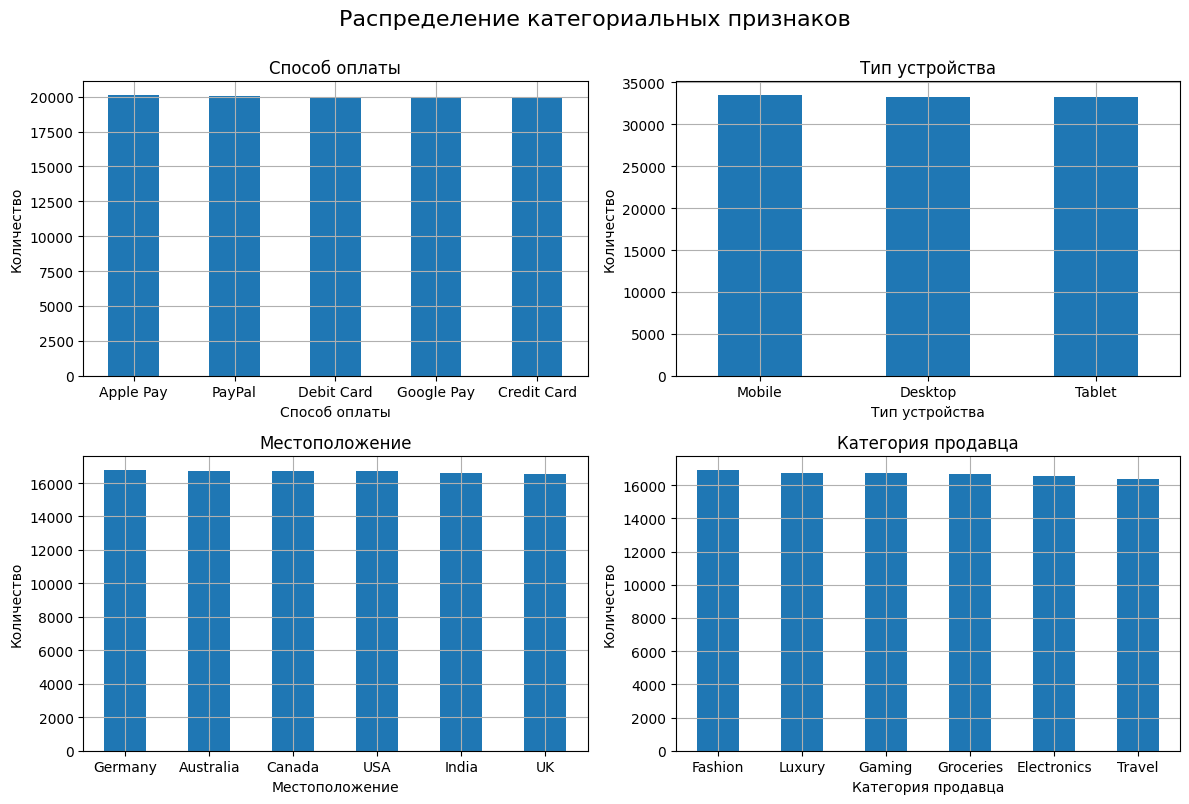

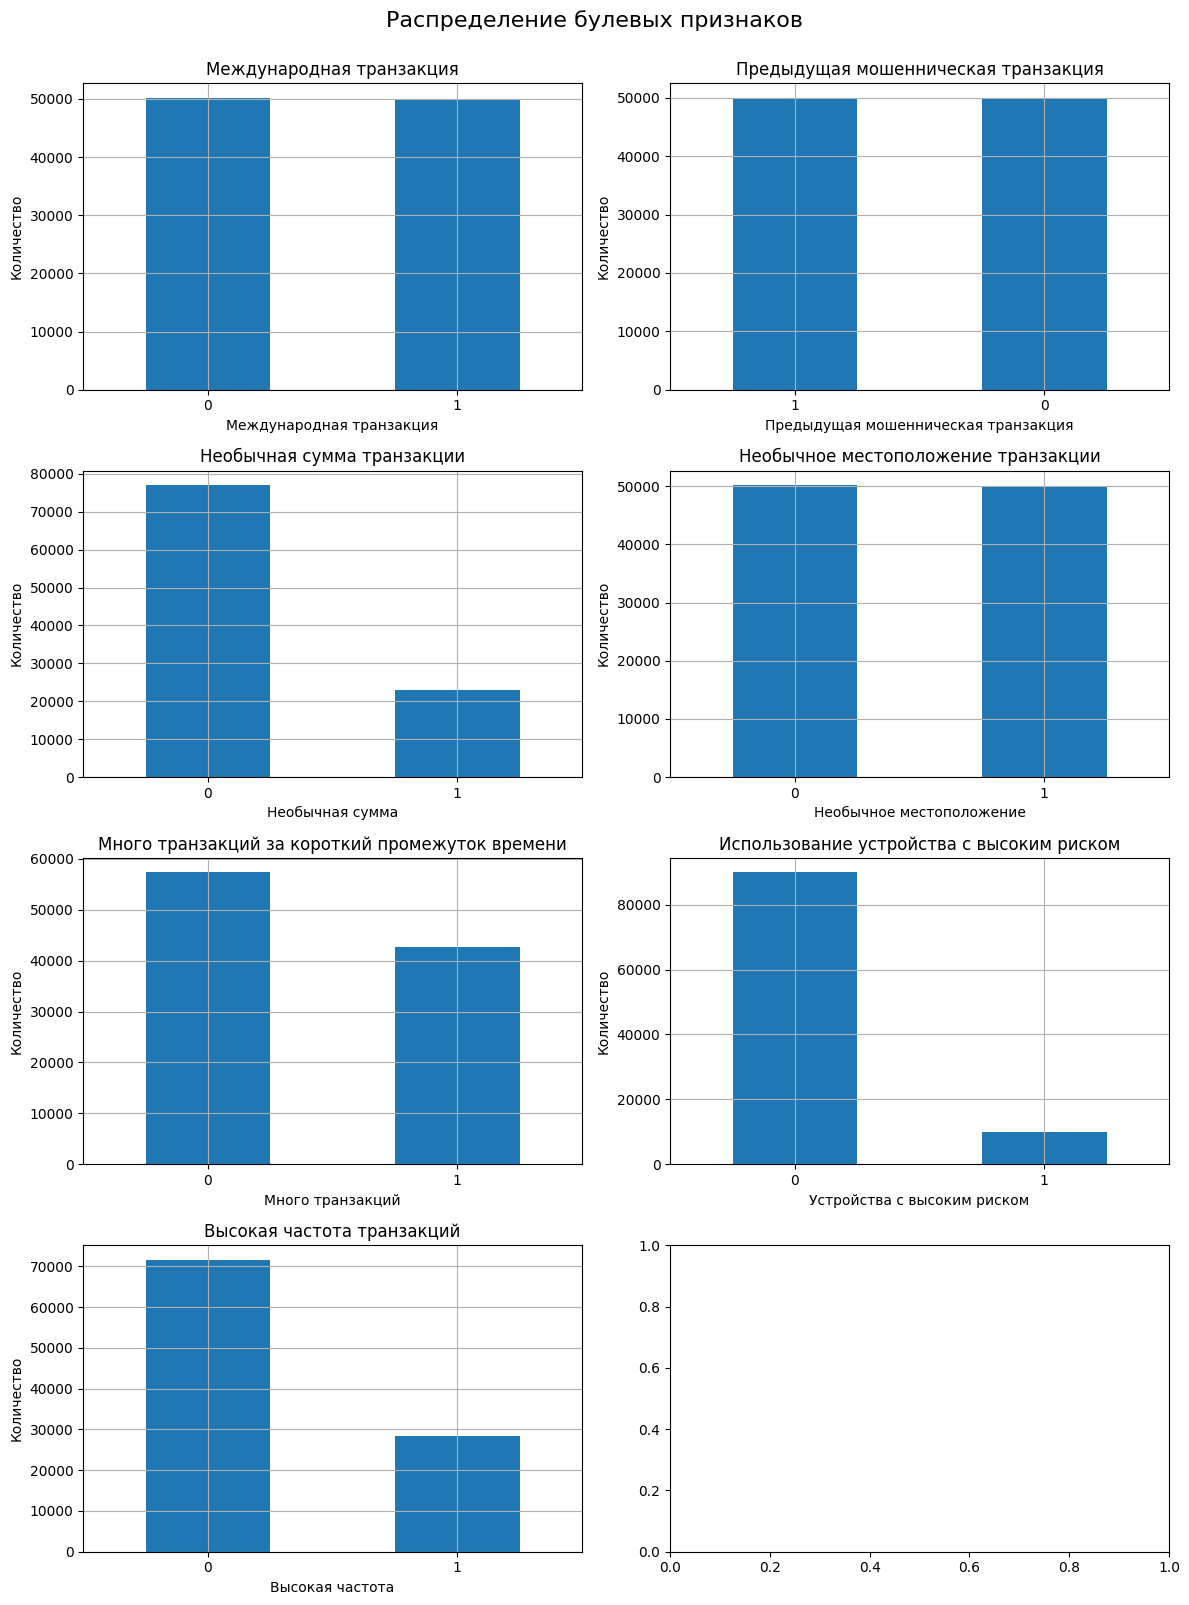

In [8]:
CAT_FEATURES = [
    'payment_method',
    'device_type',
    'location',
    'merchant_category'
]

BOOL_FEATURES = [
    'is_international',
    'previous_fraud_flag',
    'unusual_amount_flag',
    'unusual_location_flag',
    'multiple_transactions_short_time',
    'high_risk_device_flag',
    'velocity_flag'
]

cat_feat_desc = [
    {"data": df['payment_method'].value_counts(), "title": "Способ оплаты", "xlabel": "Способ оплаты", "ylabel": "Количество"},
    {"data": df['device_type'].value_counts(), "title": "Тип устройства", "xlabel": "Тип устройства", "ylabel": "Количество"},
    {"data": df['location'].value_counts(), "title": "Местоположение", "xlabel": "Местоположение", "ylabel": "Количество"},
    {"data": df['merchant_category'].value_counts(), "title": "Категория продавца", "xlabel": "Категория продавца", "ylabel": "Количество"}
]

bool_feat_desc = [
    {"data": df['is_international'].value_counts(), "title": "Международная транзакция", "xlabel": "Международная транзакция", "ylabel": "Количество"},
    {"data": df['previous_fraud_flag'].value_counts(), "title": "Предыдущая мошенническая транзакция", "xlabel": "Предыдущая мошенническая транзакция", "ylabel": "Количество"},
    {"data": df['unusual_amount_flag'].value_counts(), "title": "Необычная сумма транзакции", "xlabel": "Необычная сумма", "ylabel": "Количество"},
    {"data": df['unusual_location_flag'].value_counts(), "title": "Необычное местоположение транзакции", "xlabel": "Необычное местоположение", "ylabel": "Количество"},
    {"data": df['multiple_transactions_short_time'].value_counts(), "title": "Много транзакций за короткий промежуток времени", "xlabel": "Много транзакций", "ylabel": "Количество"},
    {"data": df['high_risk_device_flag'].value_counts(), "title": "Использование устройства с высоким риском", "xlabel": "Устройства с высоким риском", "ylabel": "Количество"},
    {"data": df['velocity_flag'].value_counts(), "title": "Высокая частота транзакций", "xlabel": "Высокая частота", "ylabel": "Количество"}
]

pu.show_barplot_grid(cat_feat_desc, "Распределение категориальных признаков")
pu.show_barplot_grid(bool_feat_desc, "Распределение булевых признаков")

- Категориальные признаки распределены равномерно.
- Дисбаланс наблюдается у булевых признаков `unusual_amount_flag`, `high_risk_device_flag`, `velocity_flag`, `high_risk_device_flag` - больше записей со значением `False`.

### 2.4. Проверка гипотез

#### 2.4.1 Гипотеза $H_1$: Фрод чаще встречается среди международных транзакций

In [9]:
LEVEL = 0.05

def chi2_hypothesis_test(df, feature):
    cross_table = pd.crosstab(df[feature], df[TARGET], colnames=[TARGET], rownames=[feature])
    display(cross_table)
    chi2, p, dof, expected = chi2_contingency(cross_table)
    print(f"Chi2: {chi2}, p-value: {p:.10f}")
    if p < LEVEL:
        print(f"Отклоняем нулевую гипотезу: {feature} и {TARGET} зависимы") 
    else:
        print(f"Не отклоняем нулевую гипотезу: {feature} и {TARGET} независимы")
    return chi2, p, dof, expected

chi2, p, dof, expected = chi2_hypothesis_test(df, 'is_international')


fraud_flag,0,1
is_international,,
0,36908,13288
1,15582,34218


Chi2: 17882.74738248252, p-value: 0.0000000000
Отклоняем нулевую гипотезу: is_international и fraud_flag зависимы


#### 2.4.1 Гипотеза $H_1$: Мошеннические операции чаще проходят через одни и те же методы оплаты

In [10]:
chi2, p, dof, expected = chi2_hypothesis_test(df, 'payment_method')

fraud_flag,0,1
payment_method,,
Apple Pay,10602,9495
Credit Card,10424,9517
Debit Card,10468,9490
Google Pay,10447,9504
PayPal,10549,9500


Chi2: 1.2034288118291563, p-value: 0.8775337642
Не отклоняем нулевую гипотезу: payment_method и fraud_flag независимы


#### 2.4.2 Гипотеза $H_1$: Мошенничество чаще происходит в определённые дни недели

In [11]:
chi2, p, dof, expected = chi2_hypothesis_test(df, 'transaction_dow')

fraud_flag,0,1
transaction_dow,,
0,7391,6661
1,7508,6778
2,7690,6901
3,7677,6766
4,7463,6737
5,7342,6758
6,7419,6905


Chi2: 6.707073110119463, p-value: 0.3487882872
Не отклоняем нулевую гипотезу: transaction_dow и fraud_flag независимы


#### 2.4.3 Гипотеза $H_1$: Для фрода чаще используются высокорисковые устройства

In [12]:
chi2, p, dof, expected = chi2_hypothesis_test(df, 'high_risk_device_flag')

fraud_flag,0,1
high_risk_device_flag,,
0,49092,40808
1,3398,6698


Chi2: 1596.705516541705, p-value: 0.0000000000
Отклоняем нулевую гипотезу: high_risk_device_flag и fraud_flag зависимы


- Существует связь мошеннических операций с международными транзакциями и использованием высокорисковых устройств.
- Связь мошеннических операций с методами оплаты и днями недели не находит подтверждения.

### 2.5. Анализ корреляции признаков и целевой переменной

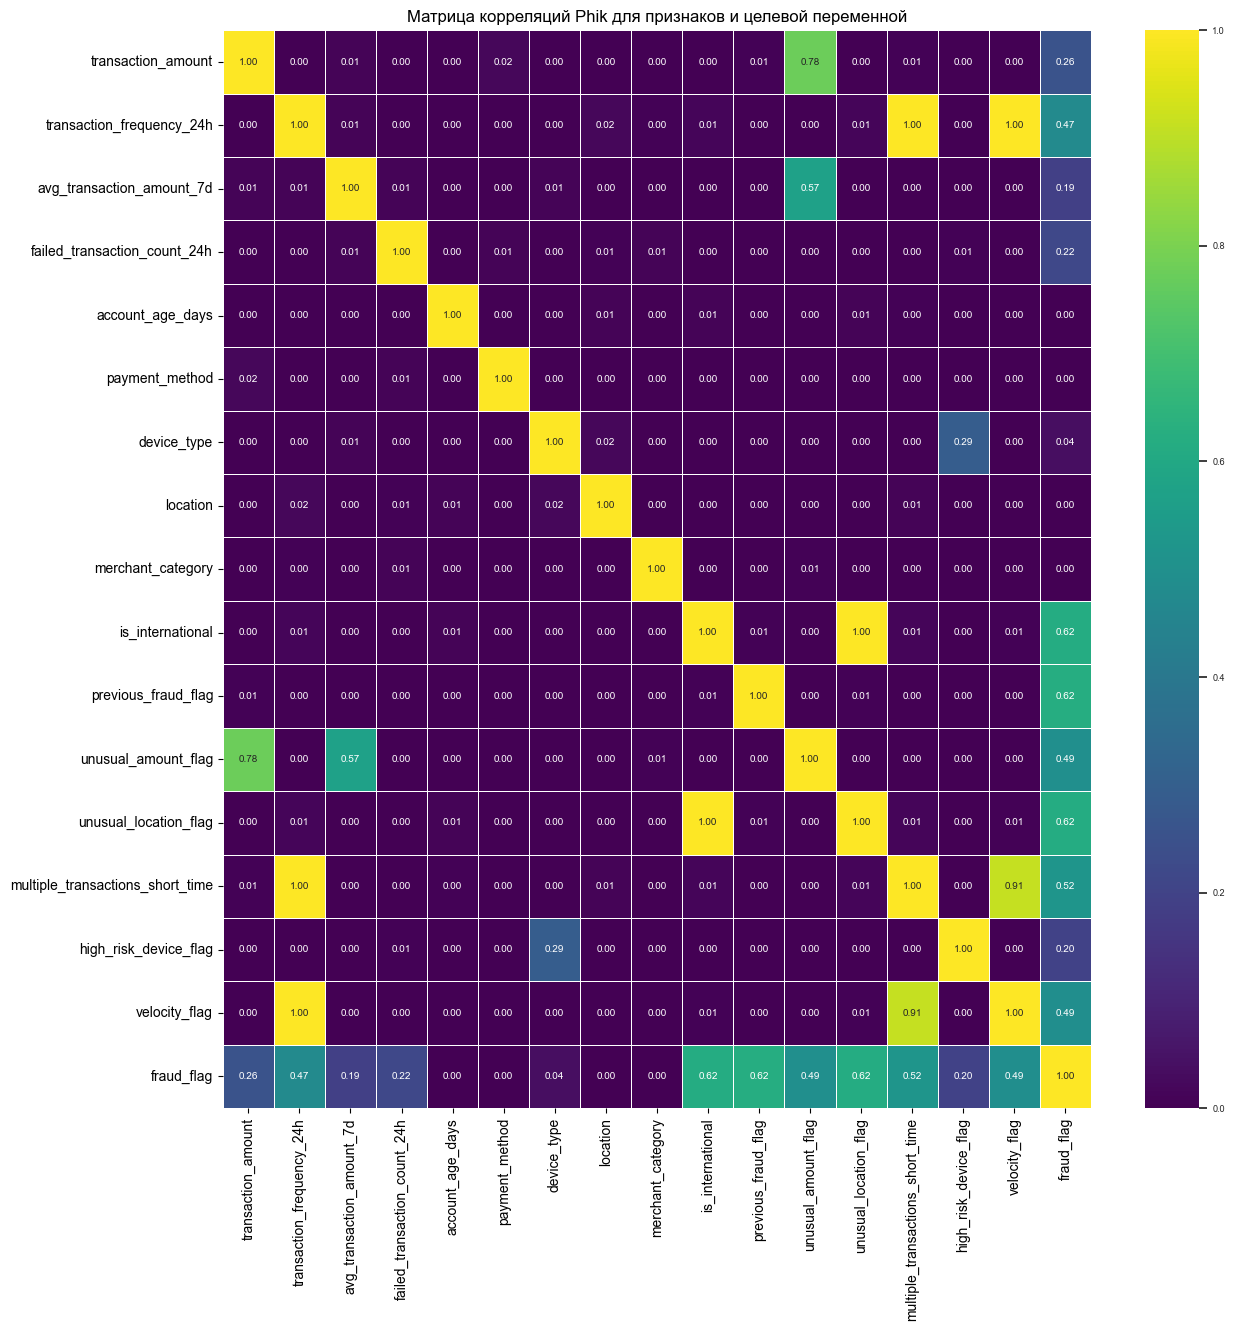

In [13]:
df_ml = df[NUMBER_FEATURES + CAT_FEATURES + BOOL_FEATURES + [TARGET]].copy()
phik_matrix = df_ml.phik_matrix(interval_cols=NUMBER_FEATURES)
pu.draw_heatmap(phik_matrix, "Матрица корреляций Phik для признаков и целевой переменной")

- Целевая переменная сильнее всего коррелирует с флагами (международная транзакция, наличие фрода в прошлом, необычная сумма, необычная локация, много транзакций за короткое время, высокая скорость транзакций). Также сильна корреляция с частотой транзакций за 24 часа.
- Есть пары признаков, которые коррелируют с коэффициентом 1, т.е. практически совпадают. Это `multiple_transactions_short_time`/`transaction_frequency_24h`, `velocity_flag`/`transaction_frequency_24h`, `unusual_location_flag`/`is_international`. Из этих признаков можно оставить только 2 - `velocity_flag` и `is_international`

## 3. Обучение модели `XGBClassifier`
### 3.1. Разделение датасета на обучающую и валидационную выборки

In [14]:
X = df_ml.drop(columns=TARGET)
y = df_ml[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y)

print(f"Количество записей в X_train: {X_test.shape[0]}")
print(f"Количество записей в X_test: {X_test.shape[0]}")

Количество записей в X_train: 20000
Количество записей в X_test: 20000


### 3.2. Пайплайн предобработки и обучения модели

In [15]:
# Функция создания пайплайна
def create_pipeline(model):
    preprocess_pp = ColumnTransformer([
        ("ohe", OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='first'),
         CAT_FEATURES),
    ], remainder='passthrough')

    pp = Pipeline([
        ("preprocess", preprocess_pp),
        ("model", model)
    ])

    return pp

# model = XGBClassifier()
# pp = create_pipeline(model)

# pp.fit(X_train, y_train)
# y_pp_test = pp.predict(X_test)

# print(classification_report(y_test, y_pp_test))
# print(confusion_matrix(y_test, y_pp_test))


### 3.3. Инициализация MLFlow

In [16]:
load_dotenv()

# Ссылка на MLflow должна быть прописана в .env как MLFLOW_TRACKING_URI
mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])

client = mlflow.MlflowClient()

experiment = mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT_NAME)

if not experiment:
    mlflow.create_experiment(MLFLOW_EXPERIMENT_NAME)
else:
    mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)

### 3.4. Функция запуска модели и записи артефактов

2026/11/13 09:06:17 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


🏃 View run xgboost_max_depth=3_learning_rate=0.01_n_estimators=100 at: https://mlflow-ds-20260728-6ce7e7aa05.infra.data-science.education-services.ru/#/experiments/7/runs/e19c15c83a2c4f24a6bfe590c3868c3a
🧪 View experiment at: https://mlflow-ds-20260728-6ce7e7aa05.infra.data-science.education-services.ru/#/experiments/7


2026/11/13 09:06:40 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


🏃 View run xgboost_max_depth=3_learning_rate=0.01_n_estimators=200 at: https://mlflow-ds-20260728-6ce7e7aa05.infra.data-science.education-services.ru/#/experiments/7/runs/920ba0fca63f4216a664fe6a80a2931d
🧪 View experiment at: https://mlflow-ds-20260728-6ce7e7aa05.infra.data-science.education-services.ru/#/experiments/7


2026/11/13 09:07:03 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


🏃 View run xgboost_max_depth=3_learning_rate=0.1_n_estimators=100 at: https://mlflow-ds-20260728-6ce7e7aa05.infra.data-science.education-services.ru/#/experiments/7/runs/4a28c96f75d840589b29bfc9266c91e8
🧪 View experiment at: https://mlflow-ds-20260728-6ce7e7aa05.infra.data-science.education-services.ru/#/experiments/7


... (14 outputs left out)

2026/11/13 09:10:44 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


🏃 View run xgboost_max_depth=7_learning_rate=0.1_n_estimators=100 at: https://mlflow-ds-20260728-6ce7e7aa05.infra.data-science.education-services.ru/#/experiments/7/runs/251324b5bb64469494875b2f1c5b7f36
🧪 View experiment at: https://mlflow-ds-20260728-6ce7e7aa05.infra.data-science.education-services.ru/#/experiments/7


2026/11/13 09:11:07 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


🏃 View run xgboost_max_depth=7_learning_rate=0.1_n_estimators=200 at: https://mlflow-ds-20260728-6ce7e7aa05.infra.data-science.education-services.ru/#/experiments/7/runs/f6a6d4b4112944568ade6e45e5ea9180
🧪 View experiment at: https://mlflow-ds-20260728-6ce7e7aa05.infra.data-science.education-services.ru/#/experiments/7


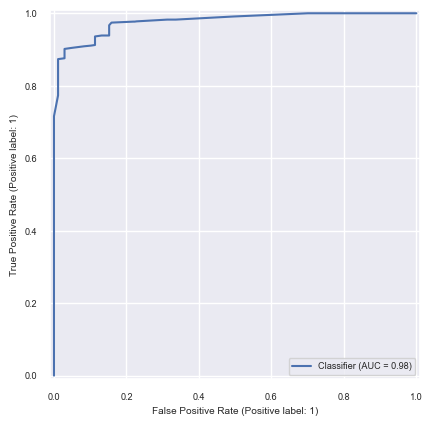

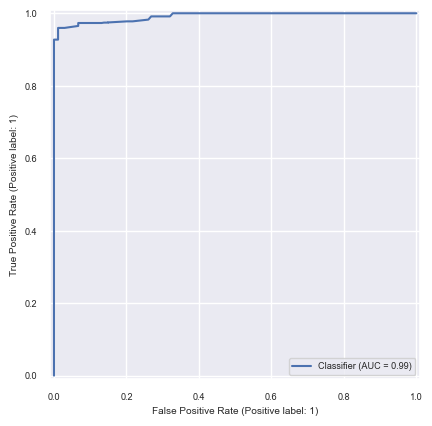

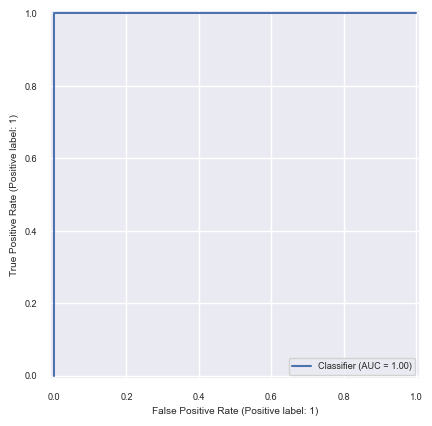

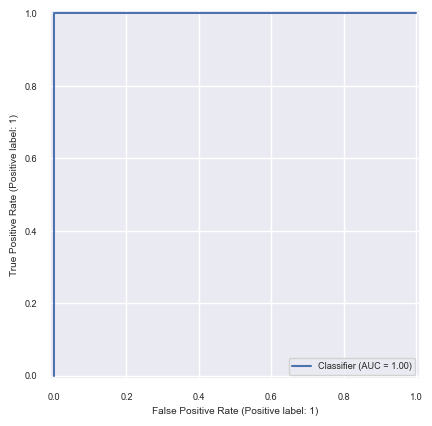

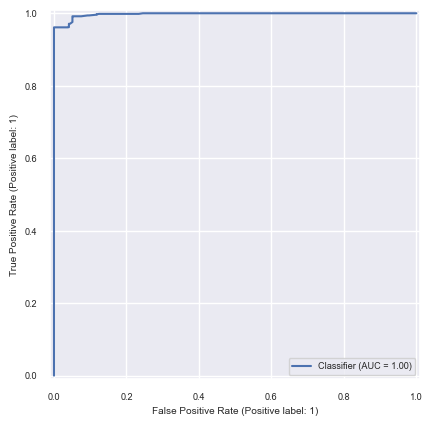

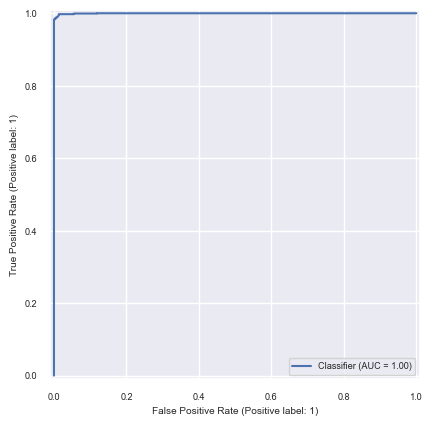

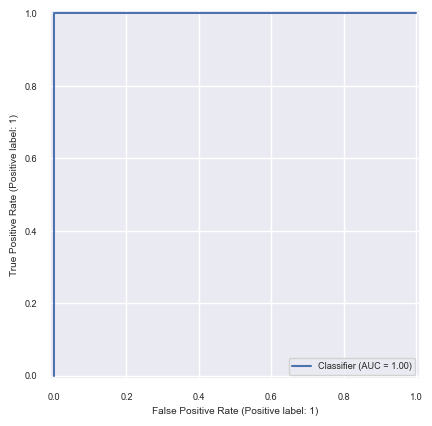

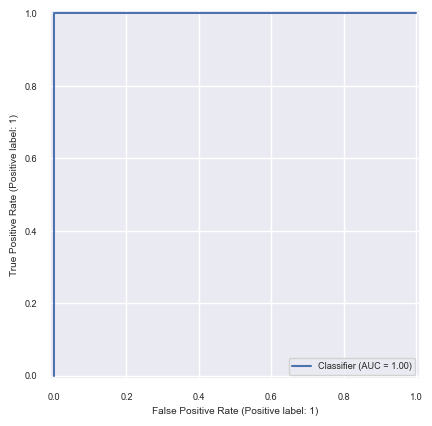

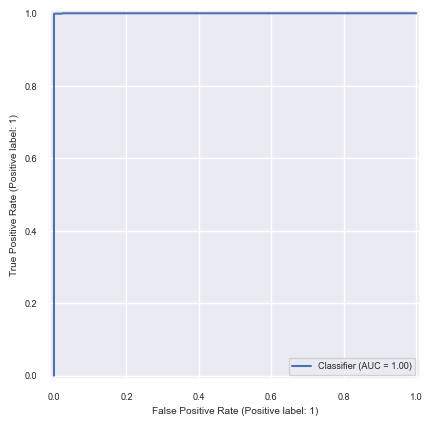

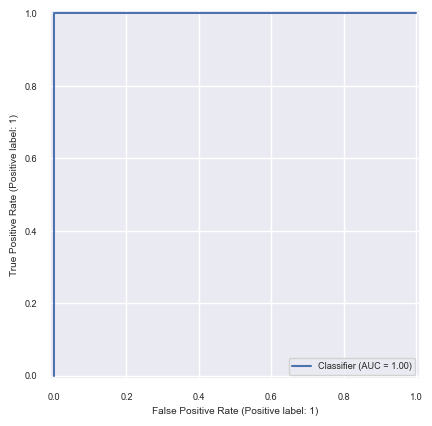

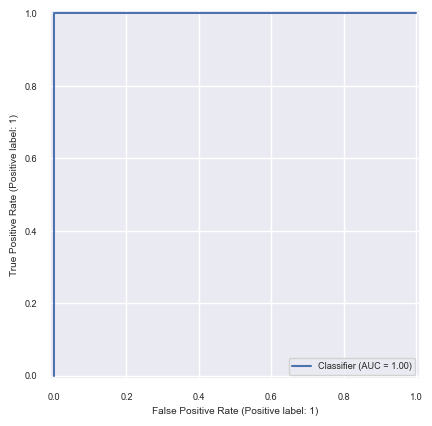

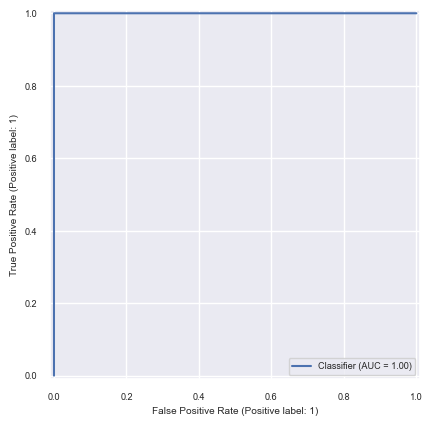

In [ ]:
def log_run(params, X_train, y_train, X_test, y_test):
    model = XGBClassifier(**params)
    pipeline = create_pipeline(model)
    run_name = "xgboost_" + "_".join([key + "=" + str(value) for key, value in params.items()])

    with mlflow.start_run(run_name=run_name):
        pipeline.fit(X_train, y_train)
        y_pred_test = pipeline.predict(X_test)
        y_pred_test_prob = pipeline.predict_proba(X_test)
        mlflow.sklearn.log_model(sk_model=pipeline,
                                name="xgboost_model")

        local_filename = "xgb_model.pkl"
        joblib.dump(pipeline, local_filename)
        mlflow.log_artifact(local_path=local_filename)
        os.remove(local_filename)
        
        mlflow.log_params(params)
        mlflow.log_metric('accuracy', accuracy_score(y_test, y_pred_test))
        mlflow.log_metric('precision', precision_score(y_test, y_pred_test))
        mlflow.log_metric('recall', recall_score(y_test, y_pred_test))
        mlflow.log_metric('f1', f1_score(y_test, y_pred_test))
        mlflow.log_metric('roc_auc', roc_auc_score(y_test, y_pred_test_prob[:,1]))

        conf_matrix = confusion_matrix(y_test, y_pred_test)
        disp = ConfusionMatrixDisplay(conf_matrix)
        disp.plot()
        fig = disp.figure_
        mlflow.log_figure(fig, "confusion_matrix.png")
        plt.close(disp.figure_)

        roc_display = RocCurveDisplay.from_predictions(y_test, y_pred_test_prob[:,1])
        fig = roc_display.figure_
        mlflow.log_figure(fig, "roc_curve.png") 
        plt.close(disp.figure_)

        preprocessor = pipeline[:-1]
        X_test_transformed = preprocessor.transform(X_test)
        feature_names = preprocessor.get_feature_names_out()
        X_test_transformed = pd.DataFrame(
            X_test_transformed,
            columns=feature_names,
            index=X_test.index
        )
        explainer = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(X_test_transformed)
        fig = plt.figure(figsize=(10, 8))
        shap.summary_plot(shap_values, X_test_transformed, show=False)
        plt.title("SHAP Summary Plot", fontsize=16)
        plt.tight_layout()
        mlflow.log_figure(fig, "shap_summary_plot.png") 
        plt.close(fig)

        train_sizes, train_scores, test_scores = learning_curve(
            estimator=create_pipeline(XGBClassifier(**params)),
            X=X_train,
            y=y_train,
            cv=5,
            scoring='roc_auc',
            train_sizes=np.linspace(0.1, 1.0, 10),
            n_jobs=-1
        )
        train_mean = train_scores.mean(axis=1)
        train_std = train_scores.std(axis=1)

        test_mean = test_scores.mean(axis=1)
        test_std = test_scores.std(axis=1)

        fig, ax = plt.subplots(figsize=(10, 6))

        ax.plot(train_sizes, train_mean, label='Training score')
        ax.plot(train_sizes, test_mean, label='Cross-validation score')

        ax.fill_between(
            train_sizes,
            train_mean - train_std,
            train_mean + train_std,
            alpha=0.15
        )

        ax.fill_between(
            train_sizes,
            test_mean - test_std,
            test_mean + test_std,
            alpha=0.15
        )

        ax.set_xlabel('Training examples')
        ax.set_ylabel('ROC AUC')
        ax.set_title('Learning Curve')
        ax.legend()
        ax.grid()

        fig.tight_layout()

        mlflow.log_figure(fig, "learning_curve.png")

        plt.close(fig)


param_sets = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1],
    'n_estimators': [100, 200]
}

keys = param_sets.keys()

combinations = [
    dict(zip(keys, values))
    for values in product(*param_sets.values())
]

for params in combinations:
    log_run(params, X_train, y_train, X_test, y_test)

In [18]:
experiment = mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT_NAME)

runs_df = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id]
)

runs_df = runs_df[runs_df['status'] == 'FINISHED']

runs_df['sum_metrics'] = (runs_df['metrics.accuracy'] +
                          runs_df['metrics.precision'] +
                          runs_df['metrics.recall'] +
                          runs_df['metrics.f1'])

runs_df.sort_values(by=['metrics.roc_auc', 'sum_metrics'], ascending=False)
runs_df.head()

champion_run_id = runs_df.loc[0, 'run_id']

run = client.get_run(champion_run_id)
print("Выходные модели рана:", run.outputs.model_outputs)

champion_uri = f"models:/{run.outputs.model_outputs[0].model_id}"
result = mlflow.register_model(model_uri=champion_uri, name=MLFLOW_REGISTRY_MODEL_NAME)

print(f"Модель зарегистрирована. Имя: {result.name}, Версия: {result.version}")

Выходные модели рана: [<LoggedModelOutput: model_id='m-51abd468523243068d733fe66485d85e', step=0>]


Registered model 'FraudDetectionModel' already exists. Creating a new version of this model...
2026/11/13 09:11:32 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: FraudDetectionModel, version 3
Created version '3' of model 'FraudDetectionModel'.


Модель зарегистрирована. Имя: FraudDetectionModel, Версия: 3
